# Graph-based EPV modeling pipeline

**Analytical question:** Construct and train a graph scoring model.

**Stages in this notebook:** Features; distances; adjacency; normalization; messages; pooling; gradients; training; ten-second labels.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Real-data extension:** after the synthetic derivative checks, this notebook trains an explicit frame GNN on SkillCorner tracking and reconstructed ten-second scoring labels, evaluates whole unseen matches, and animates its actual held-out predictions. All data, model, optimizer and animation code remains inline. A saved teaching checkpoint makes presentation playback quick; set `RETRAIN=True` to rerun the included training loop.


**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

## Reading the code

Each statement performs one step. Names describe the values being calculated, and comments explain the purpose or units. A `for` loop repeats the indented steps for each player, frame or example. A function groups steps that we reuse later.

`pandas` tables hold the data. Square brackets select columns or rows; a condition such as `distance < 2` creates a True/False filter. `NumPy` arrays hold numbers for the calculations. `axis=0` refers to rows and `axis=1` to columns in a two-dimensional array. Shape comments explain additional dimensions where needed.

Run the worked calculations in order before using the final exploration section. The plotting and file-loading functions are included here so the notebook runs on its own.

Use `and` to combine individual True/False values. Use `&` to combine whole pandas columns of conditions. `np.hypot(dx, dy)` calculates distance from horizontal and vertical differences. `np.column_stack` joins columns, while `np.concatenate` joins existing arrays.

In [1]:
from pathlib import Path
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT_items_1 = []
for p in candidates:
    if (p / "data/1925299/1925299_match.json").exists():
        ROOT_items_1.append(p)
if len(ROOT_items_1) > 0:
    ROOT = ROOT_items_1[0]
else:
    ROOT = Path.cwd()
DATA_ROOT = ROOT / "data/1925299"


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = None  # None uses goal/non-goal sequence period automatically
FRAME_ID = None  # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None  # possession_index from available_possessions near the end
EVENT_ID = None  # actual supplied event_id from available_events, not row number
PLAYER_ID = None  # player_id (string or integer), from metadata
TEAM_ID = None  # team_id; None uses the initial possession team
DURATION_S = 30.0  # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3  # use 1 for every 10 Hz frame; 3 gives a faster preview
SEQUENCE = "goal"  # goal, non_goal, or sample; frame/possession can override


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True, exist_ok=True)
    revision = "4340d274572876239c154c90bc507a9b3250a656"
    base = f"https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/"
    for suffix in ["match.json", "dynamic_events.csv", "phases_of_play.csv"]:
        name = "1925299_" + suffix
        target = destination / name
        if not target.exists():
            with urllib.request.urlopen(base + name, timeout=90) as response:
                target.write_bytes(response.read())
    name = "1925299_tracking_extrapolated.jsonl"
    target = destination / name
    if not target.exists():
        url = (
            base.replace(
                "raw.githubusercontent.com/", "media.githubusercontent.com/media/"
            )
            + name
        )
        temporary = destination / (name + ".partial")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open(
            "wb"
        ) as output:
            count = 0
            for line in response:
                if line.strip():
                    json.loads(line)
                    output.write(line)
                    count += 1
                if count >= 9000:
                    break
        temporary.replace(target)


def read_tracking(destination):
    """Load the sample and make one table row for each player in each frame."""
    dataset = skillcorner.load(
        meta_data=destination / "1925299_match.json",
        raw_data=destination / "1925299_tracking_extrapolated.jsonl",
        coordinates="skillcorner",
    )
    wide = dataset.to_df()
    metadata_file = destination / "1925299_match.json"
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))

    # Each line in the tracking file is one JSON record.
    raw_records = []
    tracking_file = destination / "1925299_tracking_extrapolated.jsonl"
    for line in tracking_file.read_text().splitlines():
        if line.strip():
            raw_records.append(json.loads(line))

    # Dictionaries let us look up a value using a frame or player identifier.
    player_possession = {}
    visibility = {}
    for record in raw_records:
        frame_number = record["frame"]
        possession = record.get("possession", {})
        (player_possession[frame_number]) = str(possession.get("player_id"))
        for player in record.get("player_data", []):
            player_id = str(player["player_id"])
            (visibility[frame_number, player_id]) = player.get("is_detected")

    player_tables = []
    for player in metadata["players"]:
        player_id = str(player["id"])
        x_column = player_id + "_x"
        y_column = player_id + "_y"
        if x_column not in wide.columns:
            continue
        columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "ball_owning_team_id",
            x_column,
            y_column,
        ]
        player_table = wide[columns].copy()
        player_table.columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "team_in_possession",
            "x",
            "y",
        ]
        (player_table["player_id"]) = player_id
        (player_table["team_id"]) = player["team_id"]
        (player_table["name"]) = player["short_name"]
        player_tables.append(player_table)

    tracking = pd.concat(player_tables, ignore_index=True)
    (tracking["seconds"]) = tracking["timestamp"].dt.total_seconds()
    (tracking["player_in_possession"]) = tracking["frame_id"].map(player_possession)
    detection_flags = []
    for row in tracking.itertuples():
        detection_flags.append(visibility.get((row.frame_id, row.player_id)))
    (tracking["is_detected"]) = detection_flags
    tracking = tracking.sort_values(["player_id", "period_id", "frame_id"])
    return dataset, wide, tracking, metadata, raw_records


def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5.5))
    ax.set_facecolor("#eef3ed")
    ax.add_patch(Rectangle((-52.5, -34), 105, 68, fill=False, color="#597063"))
    ax.plot([0, 0], [-34, 34], c="#597063")
    ax.add_patch(Circle((0, 0), 9.15, fill=False, color="#597063"))
    for x in [-52.5, 36]:
        ax.add_patch(Rectangle((x, -20.16), 16.5, 40.32, fill=False, color="#597063"))
    ax.set(
        xlim=(-55, 55), ylim=(-36, 36), aspect="equal", xlabel="x (m)", ylabel="y (m)"
    )
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset, wide, tracking, metadata, raw = read_tracking(DATA_ROOT)
events = pd.read_csv(DATA_ROOT / "1925299_dynamic_events.csv")
phases = pd.read_csv(DATA_ROOT / "1925299_phases_of_play.csv")
observed = tracking.dropna(subset=["x", "y"])
complete = observed.groupby(["period_id", "frame_id"]).size()
if FRAME_ID is not None:
    frame_id = int(FRAME_ID)
else:
    frame_id = int(complete[complete == 22].index[20][1])
snapshot = observed[observed.frame_id == frame_id].copy()
keepers = set()
for p in metadata["players"]:
    if "goalkeeper" in p["player_role"]["name"].lower():
        keepers.add(str(p["id"]))
role_labels = {}
for p in metadata["players"]:
    (role_labels[str(p["id"])]) = p["player_role"]["acronym"]
assert not tracking.duplicated(["period_id", "frame_id", "player_id"]).any()
display(
    tracking[["period_id", "frame_id", "player_id", "x", "y", "is_detected"]].head(3)
)
print("Real bounded sample. Diagnostic frame:", frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define the scoring target before fitting

Bekkers’ GraphEPV target is a goal by the possession team within ten seconds in the same period. Show horizon censoring on an explicit synthetic timeline.

,period_id,seconds,ball_owning_team_id,target
0,1,0,1,1.0
1,1,12,1,0.0
2,1,28,1,NaN


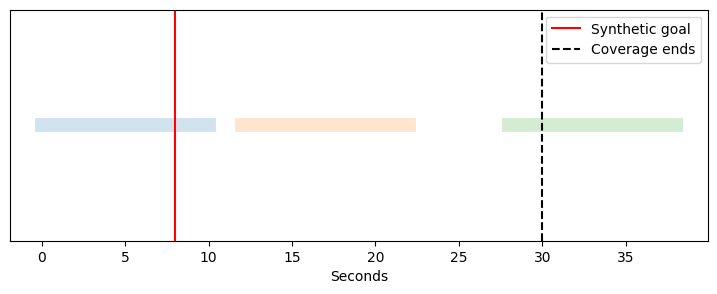

In [5]:
def goal_within_horizon(frames, goals, coverage_end, horizon=10):
    labels = pd.Series(np.nan, index=frames.index, dtype=float)
    for idx, r in frames.iterrows():
        end = coverage_end.get(r.period_id, -np.inf)
        if pd.isna(r.ball_owning_team_id) or r.seconds + horizon > end:
            continue
        eligible = (
            (goals.period == r.period_id)
            & (goals.team_id == r.ball_owning_team_id)
            & (goals.seconds > r.seconds)
            & (goals.seconds <= r.seconds + horizon)
        )
        (labels.loc[idx]) = float(eligible.any())
    return labels


toy_frames = pd.DataFrame(
    {"period_id": [1, 1, 1], "seconds": [0, 12, 28], "ball_owning_team_id": [1, 1, 1]}
)
toy_goals = pd.DataFrame({"period": [1], "seconds": [8.0], "team_id": [1]})
labels = goal_within_horizon(toy_frames, toy_goals, {1: 30.0})
display(pd.concat([toy_frames, labels.rename("target")], axis=1))
assert labels.iloc[0] == 1 and labels.iloc[1] == 0 and pd.isna(labels.iloc[2])
fig, ax = plt.subplots(figsize=(9, 3))
for t in toy_frames.seconds:
    ax.plot([t, t + 10], [0, 0], lw=10, alpha=0.2)
ax.axvline(8, c="red", label="Synthetic goal")
ax.axvline(30, c="black", ls="--", label="Coverage ends")
ax.set(xlabel="Seconds", yticks=[])
ax.legend()
plt.show()


## 5. Build node features from a real frame

Inspect the feature matrix before deciding graph edges.

In [6]:
nodes = snapshot.sort_values("player_id")
ids = nodes.player_id.to_numpy()
pos = nodes[["x", "y"]].to_numpy()
X = np.column_stack((pos / np.array([52.5, 34]), (nodes.team_id == 1802).astype(float)))
display(pd.DataFrame(X, index=ids, columns=["scaled_x", "scaled_y", "home_team"]))


,scaled_x,scaled_y,home_team
11897,-0.452571,-0.264118,0.0
287934,0.102667,0.147941,1.0
50982,-0.489714,0.685882,0.0
50999,0.694286,0.025294,1.0
51002,-0.084000,0.048529,1.0
51043,-0.139429,0.952647,1.0
51050,0.164762,0.020294,1.0
51694,-0.322857,0.350882,0.0
560882,-0.141524,0.285882,1.0
560983,0.141714,-0.196176,1.0


## 6. Construct and normalize spatial adjacency

Inspect distances, thresholded edges and row normalization in calculation order.

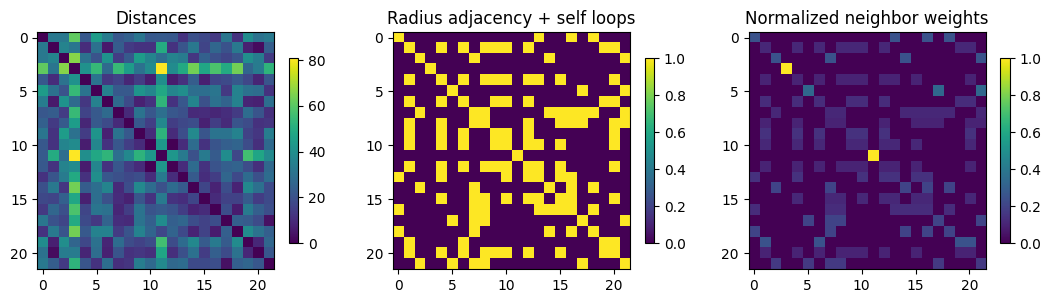

In [7]:
def adjacency_steps(position, radius):
    distance = np.sqrt(((position[:, None] - position[None]) ** 2).sum(axis=-1))
    binary = (distance <= radius).astype(float)
    normalized = binary / binary.sum(axis=1, keepdims=True)
    return distance, binary, normalized


distance, binary, A = adjacency_steps(pos, 15)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, data, title in zip(
    axs,
    [distance, binary, A],
    ["Distances", "Radius adjacency + self loops", "Normalized neighbor weights"],
):
    im = ax.imshow(data)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()
assert np.allclose(A.sum(axis=1), 1)


## 7. Aggregate neighbors, transform and pool

Inspect message passing before attaching a scoring head. Parameters here are random, not learned soccer weights.

,node,own_x,neighbor_average_x,linear_0,hidden_0
0,11897,-0.452571,-0.399905,-0.010628,-0.010627
1,287934,0.102667,0.041989,-0.160209,-0.158852
2,50982,-0.489714,-0.385714,-0.054358,-0.054305
3,50999,0.694286,0.694286,-0.240885,-0.236332
4,51002,-0.084000,-0.028000,-0.114788,-0.114287
5,51043,-0.139429,-0.181333,-0.231112,-0.227084
6,51050,0.164762,0.064929,-0.151695,-0.150542
7,51694,-0.322857,-0.332656,-0.098002,-0.097689
8,560882,-0.141524,-0.145029,-0.142356,-0.141402
9,560983,0.141714,0.043293,-0.138079,-0.137208


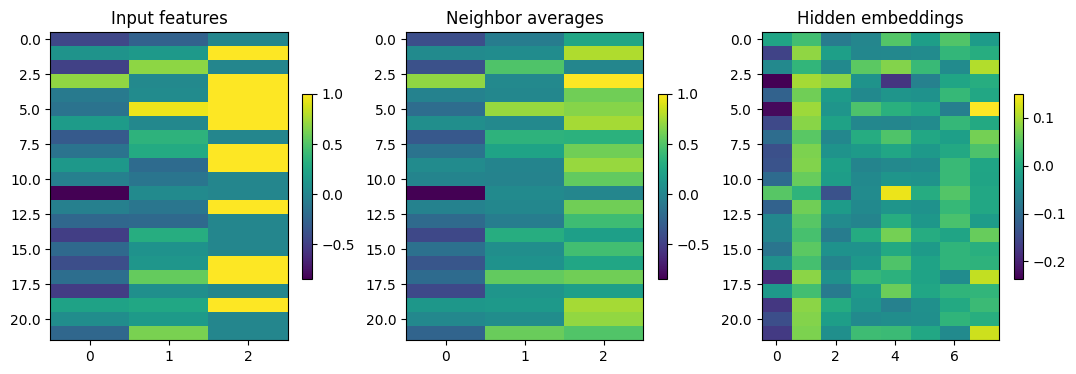

Mean-pooled graph embedding: [-0.1111  0.0614 -0.0382 -0.0273 -0.0017 -0.0246  0.0034  0.0301]


In [8]:
def message_steps(node_features, adjacency, weights):
    neighbor_average = adjacency @ node_features
    linear = neighbor_average @ weights
    hidden = np.tanh(linear)
    pooled = hidden.mean(axis=0)
    return neighbor_average, linear, hidden, pooled


rng = np.random.default_rng(4)
W = rng.normal(0, 0.1, (X.shape[1], 8))
head = rng.normal(0, 0.1, 8)
aggregate, linear, hidden, pooled = message_steps(X, A, W)
display(
    pd.DataFrame(
        {
            "node": ids,
            "own_x": X[:, 0],
            "neighbor_average_x": aggregate[:, 0],
            "linear_0": linear[:, 0],
            "hidden_0": hidden[:, 0],
        }
    ).head(10)
)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, data, title in zip(
    axs,
    [X, aggregate, hidden],
    ["Input features", "Neighbor averages", "Hidden embeddings"],
):
    im = ax.imshow(data, aspect="auto")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()
print("Mean-pooled graph embedding:", pooled.round(4))


## 8. Inspect a forward score and backward gradients

Use one labeled synthetic graph to trace loss, pooling derivatives, the tanh derivative and shared-weight gradients before training.

,analytic,finite_difference
0,-0.069253,-0.069253


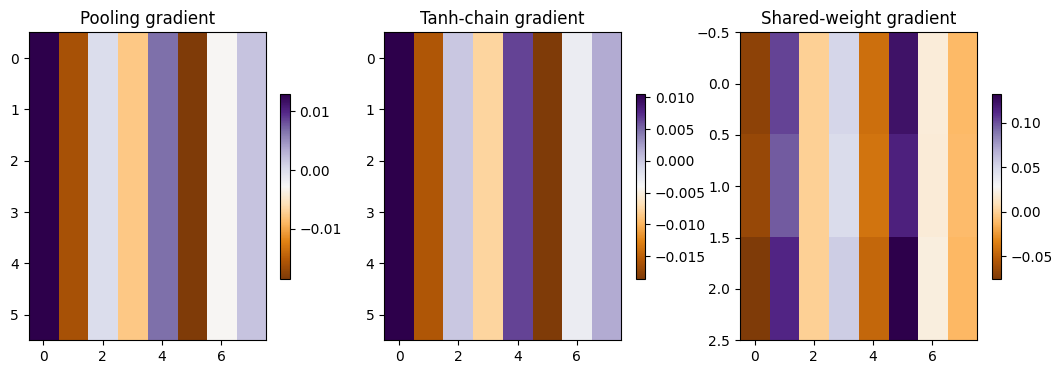

In [9]:
def graph_forward(X, A, W, head, bias):
    aggregated = A @ X
    hidden = np.tanh(aggregated @ W)
    pooled = hidden.mean(axis=0)
    score = pooled @ head + bias
    probability = 1 / (1 + np.exp(-np.clip(score, -40, 40)))
    return aggregated, hidden, pooled, score, probability


def graph_gradients(X, A, y, W, head, bias):
    aggregated, H, g, score, p = graph_forward(X, A, W, head, bias)
    error = p - y
    hidden_gradient = np.broadcast_to(error * head / len(X), H.shape)
    linear_gradient = hidden_gradient * (1 - H**2)
    gradients = {"W": aggregated.T @ linear_gradient, "head": g * error, "bias": error}
    loss = np.logaddexp(0, score) - y * score
    return loss, gradients, hidden_gradient, linear_gradient


rng = np.random.default_rng(10)
toy_X = rng.normal(-1, 0.3, (6, 3))
toy_A = np.ones((6, 6)) / 6
toy_y = 0
loss, gradient, hidden_gradient, linear_gradient = graph_gradients(
    toy_X, toy_A, toy_y, W, head, 0.0
)
epsilon = 1e-5
plus = W.copy()
minus = W.copy()
(plus[0, 0]) += epsilon
(minus[0, 0]) -= epsilon
numeric = (
    graph_gradients(toy_X, toy_A, toy_y, plus, head, 0.0)[0]
    - graph_gradients(toy_X, toy_A, toy_y, minus, head, 0.0)[0]
) / (2 * epsilon)
assert np.isclose(numeric, gradient["W"][0, 0], rtol=1e-4, atol=1e-7)
display(
    pd.DataFrame({"analytic": [gradient["W"][0, 0]], "finite_difference": [numeric]})
)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, data, title in zip(
    axs,
    [hidden_gradient, linear_gradient, gradient["W"]],
    ["Pooling gradient", "Tanh-chain gradient", "Shared-weight gradient"],
):
    im = ax.imshow(data, aspect="auto", cmap="PuOr")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()


## 9. Verify the training implementation (synthetic only)

The training loop calls the gradient helper above. Synthetic feature-sign labels verify optimization only; real GraphEPV needs many independent labeled matches.

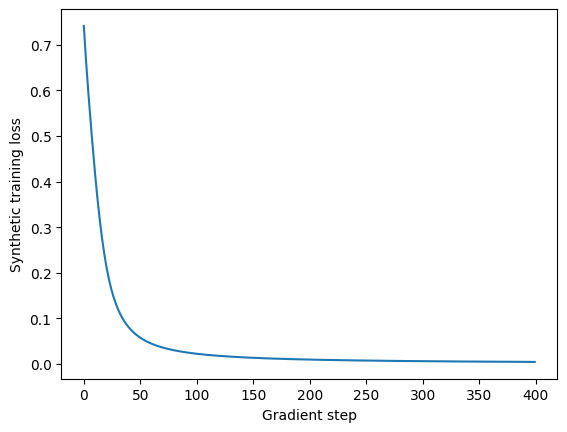

In [10]:
def train_gnn(graphs, labels, hidden=8, steps=400, lr=0.1):
    rng = np.random.default_rng(11)
    W = rng.normal(0, 0.2, (graphs[0][0].shape[1], hidden))
    head = rng.normal(0, 0.2, hidden)
    bias = 0.0
    losses = []
    for _ in range(steps):
        dW = np.zeros_like(W)
        dh = np.zeros_like(head)
        db = 0.0
        total_loss = 0.0
        for (X, A), y in zip(graphs, labels):
            loss, grad, _, _ = graph_gradients(X, A, y, W, head, bias)
            dW += grad["W"]
            dh += grad["head"]
            db += grad["bias"]
            total_loss += loss
        n = len(graphs)
        W -= lr * dW / n
        head -= lr * dh / n
        bias -= lr * db / n
        losses.append(total_loss / n)
    return W, head, bias, losses


rng = np.random.default_rng(10)
graphs = []
targets = []
for i in range(40):
    y = i % 2
    graphs.append((rng.normal(2 * y - 1, 0.3, (6, 3)), np.ones((6, 6)) / 6))
    targets.append(y)
trained_W, trained_head, trained_bias, losses = train_gnn(graphs, targets)
assert losses[-1] < losses[0]
plt.plot(losses)
plt.xlabel("Gradient step")
plt.ylabel("Synthetic training loss")
plt.show()
permutation = np.random.default_rng(3).permutation(len(X))
p = graph_forward(X, A, W, head, 0.0)[-1]
permuted = graph_forward(
    X[permutation], A[np.ix_(permutation, permutation)], W, head, 0.0
)[-1]
assert np.isclose(p, permuted)


## 10. Real training data and the ten-second target
Use the pinned SkillCorner open matches, sampling one state every two seconds. Keep current possession identity, a known period, finite ball/player positions and 22 players. Input features use **only that current frame**: player geometry, team identity, ball identity and current ball context. Neither provider EPV, future shot outcomes, future movement nor score flags enter the features.

**Target:** the team possessing the ball at this frame has a goal-shot event within the following ten seconds, in the same period. Goal markers in this dataset can be attached to assisting passes, so align each to the next same-team shot within five seconds (or a preceding shot within one second). Reconcile matched home/away goal totals with the final score and exclude any match that fails. This audits coverage, not frame-perfect timing: labels remain reconstructed and need video review for rigorous benchmarking. Censor the final ten seconds of each period.

The cache stores derived graph tensors and selected raw example windows locally, under ignored `data/`. The first run may stream substantial tracking data; later runs reuse compressed caches. The four score-audit exclusions are exposed below rather than silently treating missing goals as negative labels.

In [11]:
from pathlib import Path
import json
import urllib.request
import re
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd

REVISION = "4340d274572876239c154c90bc507a9b3250a656"
MATCH_IDS = [
    1874553,
    1886347,
    1899585,
    1925299,
    1927964,
    1953632,
    1959846,
    1986691,
    1996435,
    1996436,
    2006229,
    2006363,
    2007448,
    2007721,
    2010085,
    2011166,
    2013725,
    2015213,
    2016236,
    2017461,
]


import copy
from scipy.optimize import minimize
from IPython.display import HTML
from matplotlib.ticker import PercentFormatter

GRAPH_CACHE = ROOT / "data/skillcorner_graph_epv"


In [12]:
def cached_match_inputs(match_id, cache):
    folder = cache / str(match_id)
    folder.mkdir(parents=True, exist_ok=True)
    base = f"https://raw.githubusercontent.com/SkillCorner/opendata/{REVISION}/data/matches/{match_id}/"
    for suffix, name in [
        ("match.json", "match.json"),
        ("dynamic_events.csv", "events.csv"),
    ]:
        path = folder / name
        if not path.exists():
            with urllib.request.urlopen(
                base + f"{match_id}_{suffix}", timeout=180
            ) as response:
                payload = response.read()
            temporary = path.with_suffix(".partial")
            temporary.write_bytes(payload)
            temporary.replace(path)
    return (
        json.loads((folder / "match.json").read_text(encoding="utf-8")),
        pd.read_csv(folder / "events.csv", low_memory=False),
        base,
        folder,
    )


In [13]:
def audited_goal_events(events, metadata):
    possessions = events[events.event_type == "player_possession"]
    shots = possessions[possessions.end_type == "shot"].copy()
    markers = possessions[
        possessions.game_interruption_after == "goal_for"
    ].drop_duplicates(["period", "frame_end", "team_id"])
    used = set()
    goals = []
    unmatched = []
    for marker in markers.itertuples():
        eligible = shots[
            (shots.period == marker.period)
            & (shots.team_id == marker.team_id)
            & ~shots.index.isin(used)
        ]
        following = eligible[
            eligible.frame_end.between(marker.frame_end, marker.frame_end + 50)
        ]
        if len(following):
            idx = following.frame_end.idxmin()
        else:
            previous = eligible[
                eligible.frame_end.between(marker.frame_end - 10, marker.frame_end)
            ]
            if previous.empty:
                unmatched.append(marker.event_id)
                continue
            idx = previous.frame_end.idxmax()
        used.add(idx)
        shot = shots.loc[idx]
        goals.append(
            {
                "period": int(shot.period),
                "frame": int(shot.frame_end),
                "team_id": int(shot.team_id),
                "marker_frame": int(marker.frame_end),
                "alignment_offset_frames": int(shot.frame_end - marker.frame_end),
            }
        )
    home_items_1 = []
    for g in goals:
        home_items_1.append(g["team_id"] == int(metadata["home_team"]["id"]))
    home = sum(home_items_1)
    away_items_1 = []
    for g in goals:
        away_items_1.append(g["team_id"] == int(metadata["away_team"]["id"]))
    away = sum(away_items_1)
    passed = (
        not unmatched
        and home == int(metadata["home_team_score"])
        and away == int(metadata["away_team_score"])
    )
    return goals, dict(
        match_id=int(metadata["id"]),
        included=bool(passed),
        home_goals=home,
        away_goals=away,
        score_home=int(metadata["home_team_score"]),
        score_away=int(metadata["away_team_score"]),
        unmatched_markers=unmatched,
        goals=goals,
    )


In [14]:
def frame_to_graph(frame, metadata):
    """Only current pre-outcome tracking inputs; no provider EPV or outcome flags."""
    group = frame.get("possession", {}).get("group")
    if group not in ["home team", "away team"]:
        return None
    home_id = int(metadata["home_team"]["id"])
    away_id = int(metadata["away_team"]["id"])
    if group == "home team":
        team = home_id
    else:
        team = away_id
    player_meta = {}
    for player in metadata["players"]:
        (player_meta[str(player["id"])]) = player
    players = []
    for player in frame.get("player_data", []):
        if (
            str(player["player_id"]) in player_meta
            and player.get("x") is not None
            and (player.get("y") is not None)
        ):
            players.append(player)
    if len(players) != 22:
        return None

    def player_identifier(player):
        return str(player["player_id"])

    players = sorted(players, key=player_identifier)
    ball = frame.get("ball_data", {})
    if ball.get("x") is None or ball.get("y") is None:
        return None
    period = int(frame["period"])
    home_left = metadata["home_team_side"][period - 1] == "right_to_left"
    if team == home_id:
        left = home_left
    else:
        left = not home_left
    if left:
        sign = -1
    else:
        sign = 1
    player_xy_items_1 = []
    for player in players:
        player_xy_items_1.append([player["x"], player["y"]])
    player_xy = sign * np.array(player_xy_items_1, float)
    ball_xy = sign * np.array([ball["x"], ball["y"]], float)
    positions = np.vstack([player_xy, ball_xy])
    attacking_items_1 = []
    for player in players:
        attacking_items_1.append(
            int(player_meta[str(player["player_id"])]["team_id"]) == team
        )
    attacking = np.array(attacking_items_1)
    team_flags = np.concatenate((np.where(attacking, 1.0, -1.0), [0.0]))
    goal_x = float(metadata["pitch_length"]) / 2
    goal = np.array([goal_x, 0.0])
    ball_flag = np.concatenate((np.zeros(22), [1.0]))
    distance_goal = np.linalg.norm(positions - goal, axis=1) / 120
    distance_ball = np.linalg.norm(positions - ball_xy, axis=1) / 120
    # State features remain identical when node order is permuted consistently.
    node_features = np.column_stack(
        (
            positions[:, 0] / goal_x,
            positions[:, 1] / 34,
            np.abs(positions[:, 1]) / 34,
            distance_goal,
            distance_ball,
            team_flags,
            ball_flag,
            np.full(23, ball_xy[0] / goal_x),
            np.full(23, ball_xy[1] / 34),
        )
    )
    distance = np.linalg.norm(positions[:, None] - positions[None], axis=-1)
    adjacency = (distance <= 20).astype(float)
    (adjacency[-1, :]) = 1
    (adjacency[:, -1]) = 1
    adjacency /= adjacency.sum(axis=1, keepdims=True)
    pooling_weights = np.zeros((3, 23))
    (pooling_weights[0, :22]) = attacking / max(1, attacking.sum())
    (pooling_weights[1, :22]) = (~attacking) / max(1, (~attacking).sum())
    (pooling_weights[2, -1]) = 1
    if attacking.sum() != 11:
        return None
    return (
        node_features.astype("float32"),
        adjacency.astype("float32"),
        pooling_weights.astype("float32"),
        team,
    )


In [15]:
def goal_label(frame, period, team, goals, horizon_frames=100):
    result_items_1 = []
    for g in goals:
        result_items_1.append(
            g["period"] == period
            and g["team_id"] == team
            and (frame < g["frame"] <= frame + horizon_frames)
        )
    return int(any(result_items_1))


In [16]:
def collect_match_graphs(match_id, cache, stride=20):
    metadata, events, base, folder = cached_match_inputs(match_id, cache)
    goals, audit = audited_goal_events(events, metadata)
    if not audit["included"]:
        return None, audit
    target = folder / f"graphs_2s_v1.npz"
    example_path = folder / "goal_window_frames_v1.json"
    if target.exists() and example_path.exists():
        with np.load(target, allow_pickle=False) as z:
            arrays = {}
            for key in z.files:
                (arrays[key]) = z[key]
        audit.update(samples=len(arrays["y"]), positive_samples=int(arrays["y"].sum()))
        return arrays, audit
    periods = {}
    for p in metadata["match_periods"]:
        (periods[int(p["period"])]) = int(p["end_frame"])
    url = (
        base.replace("raw.githubusercontent.com/", "media.githubusercontent.com/media/")
        + f"{match_id}_tracking_extrapolated.jsonl"
    )
    X = []
    A = []
    P = []
    y = []
    frames = []
    period_ids = []
    teams = []
    examples = {}
    with urllib.request.urlopen(url, timeout=240) as response:
        for line in response:
            hit = re.search(rb'"frame"\s*:\s*(\d+)', line[:180])
            if not hit:
                continue
            f = int(hit.group(1))
            sample = f % stride == 0
            keep_example_items_1 = []
            for g in goals:
                keep_example_items_1.append(g["frame"] - 400 <= f <= g["frame"] + 20)
            keep_example = match_id == 1925299 and any(keep_example_items_1)
            if not sample and not keep_example:
                continue
            row = json.loads(line)
            if row.get("period") is None:
                continue
            period = int(row["period"])
            if keep_example:
                (examples[str(f)]) = row
            if not sample or period not in periods or f + 100 > periods[period]:
                continue
            graph = frame_to_graph(row, metadata)
            if graph is None:
                continue
            x, a, p, team = graph
            X.append(x)
            A.append(a)
            P.append(p)
            y.append(goal_label(f, period, team, goals))
            frames.append(f)
            period_ids.append(period)
            teams.append(team)
    arrays = dict(
        X=np.array(X),
        A=np.array(A),
        P=np.array(P),
        y=np.array(y, dtype="int8"),
        frame=np.array(frames),
        period=np.array(period_ids),
        team=np.array(teams),
        match=np.full(len(y), match_id),
    )
    np.savez_compressed(target, **arrays)
    example_path.write_text(json.dumps(examples), encoding="utf-8")
    audit.update(samples=len(y), positive_samples=int(np.sum(y)))
    print("Graphs", match_id, len(y), "positives", sum(y), flush=True)
    return arrays, audit


In [17]:
def load_real_graphs(cache, workers=4):
    cache.mkdir(parents=True, exist_ok=True)
    blocks = []
    audits = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        loop_items_1 = []
        for m in MATCH_IDS:
            loop_items_1.append(pool.submit(collect_match_graphs, m, cache))
        for future in as_completed(loop_items_1):
            arrays, audit = future.result()
            audits.append(audit)
            if arrays is not None:
                blocks.append(arrays)

    def match_identifier(match_block):
        return int(match_block["match"][0])

    blocks.sort(key=match_identifier)
    data = {}
    for key in blocks[0]:
        data_items_2 = []
        for b in blocks:
            data_items_2.append(b[key])
        (data[key]) = np.concatenate(data_items_2)
    return data, pd.DataFrame(audits).sort_values("match_id")


In [18]:
graph_data, label_audit = load_real_graphs(GRAPH_CACHE)
display(
    label_audit[
        [
            "match_id",
            "included",
            "home_goals",
            "away_goals",
            "score_home",
            "score_away",
            "samples",
            "positive_samples",
        ]
    ]
)
print(
    "Graphs:",
    len(graph_data["y"]),
    "| positive states:",
    int(graph_data["y"].sum()),
    "| included matches:",
    len(np.unique(graph_data["match"])),
)
display_items_1 = {}
for k in ["X", "A", "P"]:
    (display_items_1[k]) = graph_data[k].shape
print("Tensor shapes:", display_items_1)
assert np.isfinite(graph_data["X"]).all() and np.allclose(
    graph_data["A"].sum(axis=-1), 1
)


,match_id,included,home_goals,away_goals,score_home,score_away,samples,positive_samples
2,1874553,True,2,3,2,3,1614.0,11.0
1,1886347,False,1,0,2,0,NaN,NaN
0,1899585,False,1,1,2,1,NaN,NaN
3,1925299,True,0,1,0,1,1756.0,3.0
4,1927964,True,4,1,4,1,1833.0,21.0
5,1953632,True,1,1,1,1,1623.0,1.0
7,1959846,True,3,4,3,4,1521.0,29.0
6,1986691,True,0,1,0,1,1519.0,5.0
10,1996435,True,4,1,4,1,1602.0,21.0
8,1996436,True,2,1,2,1,1368.0,4.0


Graphs: 25047 | positive states: 169 | included matches: 16
Tensor shapes: {'X': (25047, 23, 9), 'A': (25047, 23, 23), 'P': (25047, 3, 23)}


## 11. Inspect the real graph representation
Nodes represent 22 players plus the ball. Edges connect players within 20 m, connect the ball to everyone, and include self loops; rows are normalized. Node features are normalized x/y, absolute lateral position, distance to goal/ball, attacking/defending identity, ball-node flag and current ball x/y. The residual self-feature map preserves each node's own state alongside averaged neighbors.

Pool **attacking players**, **defending players** and **the ball** separately, then concatenate those three embeddings. This minimal independent architecture is different from Bekkers' CrystalGraph model; it implements the same type of ten-second scoring question.

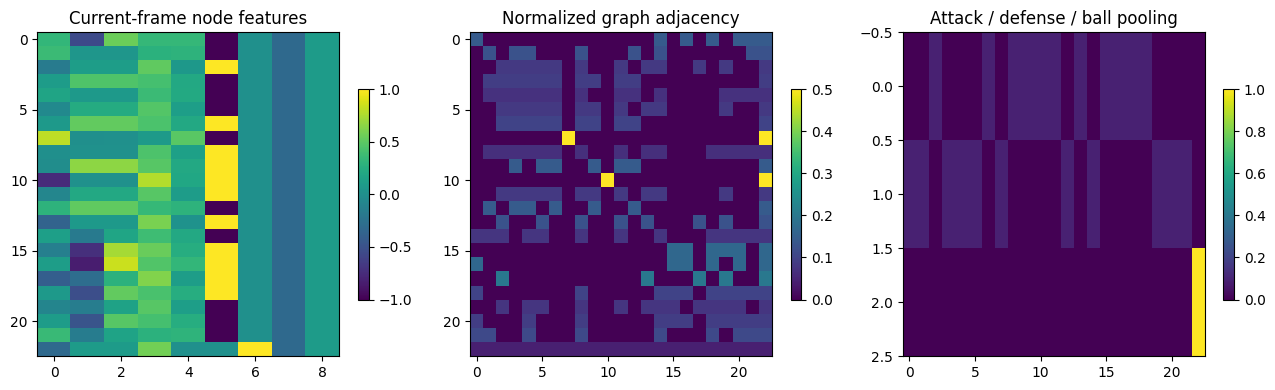

In [19]:
inspect_idx = 0
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, values, title in zip(
    axs,
    [
        graph_data["X"][inspect_idx],
        graph_data["A"][inspect_idx],
        graph_data["P"][inspect_idx],
    ],
    [
        "Current-frame node features",
        "Normalized graph adjacency",
        "Attack / defense / ball pooling",
    ],
):
    im = ax.imshow(values, aspect="auto")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.65)
plt.tight_layout()
plt.show()


## 12. Hold out whole matches before training
Reserve match 1925299 for the animation and two other deterministically selected matches for test. Select three **different** validation matches; the remaining ten train the model. No frames, positive examples or nearby label windows from one match can cross these partitions. The example match is chosen for display, not for favorable model performance. Positive counts below are **states**, not independent goals.

In [20]:
matches = np.sort(np.unique(graph_data["match"]))
others = matches[matches != 1925299]
np.random.default_rng(27).shuffle(others)
test_matches = np.concatenate(([1925299], others[:2]))
val_matches = others[2:5]
train_matches = others[5:]
train_idx = np.flatnonzero(np.isin(graph_data["match"], train_matches))
val_idx = np.flatnonzero(np.isin(graph_data["match"], val_matches))
test_idx = np.flatnonzero(np.isin(graph_data["match"], test_matches))
assert (
    not set(train_matches) & set(val_matches)
    and not set(train_matches) & set(test_matches)
    and not set(val_matches) & set(test_matches)
)
split_table_items_1 = []
for name, ids, idx in [
    ("train", train_matches, train_idx),
    ("validation", val_matches, val_idx),
    ("test", test_matches, test_idx),
]:
    split_table_items_1.append(
        {
            "split": name,
            "matches": len(ids),
            "states": len(idx),
            "positive_states": int(graph_data["y"][idx].sum()),
            "prevalence": float(graph_data["y"][idx].mean()),
        }
    )
split_table = pd.DataFrame(split_table_items_1)
display(split_table)
print(
    "Training match IDs:",
    train_matches,
    "\nValidation:",
    val_matches,
    "\nTest:",
    test_matches,
)


,split,matches,states,positive_states,prevalence
0,train,10,15695,117,0.007455
1,validation,3,4506,36,0.007989
2,test,3,4846,16,0.003302


Training match IDs: [2010085 1927964 1996436 2007721 1996435 2017461 1959846 1986691 2006363
 2015213] 
Validation: [2013725 2011166 1874553] 
Test: [1925299 1953632 2007448]


## 13. Forward pass and explicit real-data gradients
Compute `H = tanh((A @ X) @ W + X @ U + b)`, pool by team/ball, and apply a logistic head. Differentiate binary cross entropy back through the readout, pooling, tanh and both linear maps. A numerical gradient check and node-permutation check precede training.

In [21]:
def logistic(z):
    return 1 / (1 + np.exp(-np.clip(z, -40, 40)))


In [22]:
def initialize_model(features, hidden, prevalence, seed=27):
    rng = np.random.default_rng(seed)
    return {
        "W": rng.normal(0, 0.15, (features, hidden)).astype("float32"),
        "U": rng.normal(0, 0.15, (features, hidden)).astype("float32"),
        "b": np.zeros(hidden, dtype="float32"),
        "v": rng.normal(0, 0.05, 3 * hidden).astype("float32"),
        "c": np.array(np.log(prevalence / (1 - prevalence)), dtype="float32"),
    }


### The matrices used by the graph model

The equations use a batch of examples at once. `X` stores player/ball features with shape **examples × nodes × features**. `S` stores the averaged neighbor features, with the same shape. `P` stores pooling weights with shape **examples × 3 groups × nodes**; the groups are attackers, defenders and the ball.

The `@` operator performs matrix multiplication. The forward pass transforms each node, pools the groups, then produces a score. The gradient function walks backward through those same steps. `reshape` combines dimensions without changing the values; comments explain each use. The parameter names `W`, `U`, `b`, `v` and `c` match the saved model file.

In [23]:
def graph_model_forward(model, X, S, P):
    """Score a batch of graphs. X=node features, S=neighbor features, P=pooling weights."""
    neighbor_signal = S @ model["W"]
    own_signal = X @ model["U"]
    hidden_nodes = np.tanh(neighbor_signal + own_signal + model["b"])
    # Matrix multiplication pools attackers, defenders and the ball separately.
    pooled_groups = P @ hidden_nodes
    pooled_features = pooled_groups.reshape(len(X), -1)
    score = pooled_features @ model["v"] + model["c"]
    cache = (X, S, P, hidden_nodes, pooled_features)
    return score, cache


In [24]:
def graph_model_loss_gradients(model, X, S, P, y, l2=1e-5):
    """Work backward through the forward calculation to get parameter gradients."""
    score, cache = graph_model_forward(model, X, S, P)
    node_features, neighbor_features, pooling_weights, hidden_nodes, pooled_features = (
        cache
    )
    score_gradient = (logistic(score) - y) / len(y)
    pooled_gradient = score_gradient.reshape(-1, 1) * model["v"]
    group_gradient = pooled_gradient.reshape(len(X), 3, -1)
    pooling_transpose = np.transpose(pooling_weights, (0, 2, 1))
    hidden_gradient = pooling_transpose @ group_gradient
    pre_activation_gradient = hidden_gradient * (1 - hidden_nodes**2)

    # Flatten the batch and player axes so ordinary matrix multiplication can sum them.
    feature_count = X.shape[-1]
    hidden_count = hidden_nodes.shape[-1]
    flat_neighbors = neighbor_features.reshape(-1, feature_count)
    flat_nodes = node_features.reshape(-1, feature_count)
    flat_gradient = pre_activation_gradient.reshape(-1, hidden_count)
    gradients = {
        "W": flat_neighbors.T @ flat_gradient,
        "U": flat_nodes.T @ flat_gradient,
        "b": pre_activation_gradient.sum(axis=(0, 1)),
        "v": pooled_features.T @ score_gradient,
        "c": np.array(score_gradient.sum()),
    }
    loss = np.mean(np.logaddexp(0, score) - y * score)
    for key in ["W", "U", "v"]:
        loss += l2 / 2 * np.sum(model[key] ** 2)
        (gradients[key]) += l2 * model[key]
    return float(loss), gradients


In [25]:
def predict_graph_model(model, data, indices, batch=2048):
    result = []
    for start in range(0, len(indices), batch):
        idx = indices[start : start + batch]
        S = data["A"][idx] @ data["X"][idx]
        result.append(graph_model_forward(model, data["X"][idx], S, data["P"][idx])[0])
    return np.concatenate(result)


In [26]:
small = np.arange(4)
check_X = graph_data["X"][small].astype(float)
check_S = (graph_data["A"][small] @ graph_data["X"][small]).astype(float)
check_P = graph_data["P"][small].astype(float)
check_model = {}
for k, v in initialize_model(check_X.shape[-1], 4, 0.01).items():
    (check_model[k]) = np.asarray(v, dtype=float)
loss, grad = graph_model_loss_gradients(
    check_model, check_X, check_S, check_P, graph_data["y"][small]
)
eps = 1e-5
plus = copy.deepcopy(check_model)
minus = copy.deepcopy(check_model)
(plus["W"][0, 0]) += eps
(minus["W"][0, 0]) -= eps
numeric = (
    graph_model_loss_gradients(plus, check_X, check_S, check_P, graph_data["y"][small])[
        0
    ]
    - graph_model_loss_gradients(
        minus, check_X, check_S, check_P, graph_data["y"][small]
    )[0]
) / (2 * eps)
assert np.isclose(numeric, grad["W"][0, 0], rtol=1e-4, atol=1e-7)
permutation = np.random.default_rng(3).permutation(23)
before = graph_model_forward(check_model, check_X, check_S, check_P)[0]
after = graph_model_forward(
    check_model,
    check_X[:, permutation],
    check_S[:, permutation],
    check_P[:, :, permutation],
)[0]
assert np.allclose(before, after)
display(
    pd.DataFrame(
        {"analytic_gradient": [grad["W"][0, 0]], "finite_difference": [numeric]}
    )
)


,analytic_gradient,finite_difference
0,0.000048,0.000048


## 14. Train on real states, with validation early stopping
The included optimizer uses Adam, unweighted binary cross entropy, 16 hidden channels and fixed regularization. It does **not** oversample goals. Stop using validation log loss and restore the best validation checkpoint. Test matches are untouched.

The distributed checkpoint and history were trained with this exact code and split. `RETRAIN=False` keeps the walkthrough fast; set it to `True` to run training again (several minutes). If no checkpoint is available, the cell trains automatically. Cached weights are data, not a helper module; all training code remains in this notebook.

In [27]:
def fit_real_graph_model(
    data, train_idx, val_idx, epochs=150, batch_size=512, lr=0.003, patience=20
):
    y = data["y"]
    rng = np.random.default_rng(27)
    model = initialize_model(data["X"].shape[-1], 16, float(y[train_idx].mean()))
    S = data["A"] @ data["X"]
    first = {}
    for k, v in model.items():
        (first[k]) = np.zeros_like(v)
    second = {}
    for k, v in model.items():
        (second[k]) = np.zeros_like(v)
    step = 0
    history = []
    best = None
    best_loss = np.inf
    bad = 0
    for epoch in range(epochs):
        order = rng.permutation(train_idx)
        total = 0.0
        for start in range(0, len(order), batch_size):
            idx = order[start : start + batch_size]
            loss, grad = graph_model_loss_gradients(
                model, data["X"][idx], S[idx], data["P"][idx], y[idx]
            )
            step += 1
            total += loss * len(idx)
            for key in model:
                (first[key]) = 0.9 * first[key] + 0.1 * grad[key]
                (second[key]) = 0.999 * second[key] + 0.001 * grad[key] ** 2
                (model[key]) -= (
                    lr
                    * (first[key] / (1 - 0.9**step))
                    / (np.sqrt(second[key] / (1 - 0.999**step)) + 1e-8)
                )
        logits = predict_graph_model(model, data, val_idx)
        val_loss = float(np.mean(np.logaddexp(0, logits) - y[val_idx] * logits))
        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": total / len(train_idx),
                "validation_log_loss": val_loss,
            }
        )
        if val_loss < best_loss - 1e-6:
            best_loss = val_loss
            best = copy.deepcopy(model)
            bad = 0
        else:
            bad += 1
        if (epoch + 1) % 10 == 0:
            print(
                "Epoch",
                epoch + 1,
                "validation log loss",
                round(val_loss, 5),
                flush=True,
            )
        if bad >= patience:
            break
    return best, history


Loaded real-data teaching checkpoint. Set RETRAIN=True above to rerun the shown training loop.


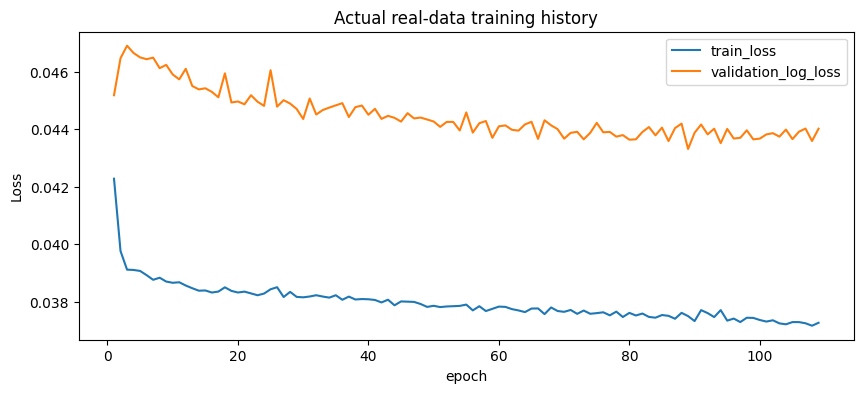

In [28]:
RETRAIN = False
checkpoint = ROOT / "resources/models/graph_epv_teaching.npz"
history_path = ROOT / "resources/models/graph_epv_training_history.json"
if RETRAIN or not checkpoint.exists() or not history_path.exists():
    real_model, training_history = fit_real_graph_model(graph_data, train_idx, val_idx)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        checkpoint,
        **real_model,
        train_matches=train_matches,
        val_matches=val_matches,
        test_matches=test_matches
    )
    history_path.write_text(json.dumps(training_history), encoding="utf-8")
    print("Trained on the declared real-data training matches.")
else:
    with np.load(checkpoint, allow_pickle=False) as saved:
        assert (
            np.array_equal(saved["train_matches"], train_matches)
            and np.array_equal(saved["val_matches"], val_matches)
            and np.array_equal(saved["test_matches"], test_matches)
        )
        real_model = {}
        for k in ["W", "U", "b", "v", "c"]:
            (real_model[k]) = saved[k].copy()
    training_history = json.loads(history_path.read_text(encoding="utf-8"))
    print(
        "Loaded real-data teaching checkpoint. Set RETRAIN=True above to rerun the shown training loop."
    )
history_table = pd.DataFrame(training_history)
history_table.plot(x="epoch", y=["train_loss", "validation_log_loss"], figsize=(10, 4))
plt.ylabel("Loss")
plt.title("Actual real-data training history")
plt.show()


## 15. Calibrate using validation matches, then evaluate unseen matches
Fit a positive-slope affine logit calibrator on validation predictions only. Compare the frozen calibrated GNN with a **training-prevalence constant baseline** on test matches. Show ROC and precision–recall: goals are rare, so average precision and the prevalence reference matter. These three test matches and correlated positive frames are far too limited to establish production quality or a GNN advantage over a strong location model.

In [29]:
def fit_calibrator(logits, y):
    def loss_grad(ab):
        a, b = ab
        z = a * logits + b
        p = logistic(z)
        e = p - y
        return np.mean(np.logaddexp(0, z) - y * z) + 0.001 * (
            (a - 1) ** 2 + b * b
        ), np.array([np.mean(e * logits) + 0.002 * (a - 1), np.mean(e) + 0.002 * b])

    result = minimize(
        loss_grad, [1.0, 0.0], jac=True, method="L-BFGS-B", bounds=[(0.1, 10), (-5, 5)]
    )
    if not result.success:
        raise RuntimeError(result.message)
    return result.x


def ranking_metrics(y, p):
    order = np.argsort(-p, kind="mergesort")
    labels = np.asarray(y)[order]
    scores = p[order]
    ends = np.concatenate((np.flatnonzero(np.diff(scores)), [len(scores) - 1]))
    tp = labels.cumsum()[ends]
    fp = ends + 1 - tp
    recall = tp / labels.sum()
    precision = tp / (tp + fp)
    fpr = np.concatenate(([0], fp / (len(y) - labels.sum())))
    tpr = np.concatenate(([0], recall))
    return {
        "roc_auc": float(np.trapezoid(tpr, fpr)),
        "average_precision": (
            float(np.sum(np.diff(np.concatenate(([0], recall))) * precision))
        ),
        "fpr": fpr,
        "tpr": tpr,
        "recall": (np.concatenate(([0], recall))),
        "precision": (np.concatenate(([1], precision))),
    }


,model,ROC_AUC,average_precision,log_loss,Brier_score,mean_prediction
0,Real trained frame GNN,0.842547,0.020143,0.021583,0.003335,0.008585
1,Training-prevalence baseline,0.500000,0.003302,0.023633,0.003308,0.007455


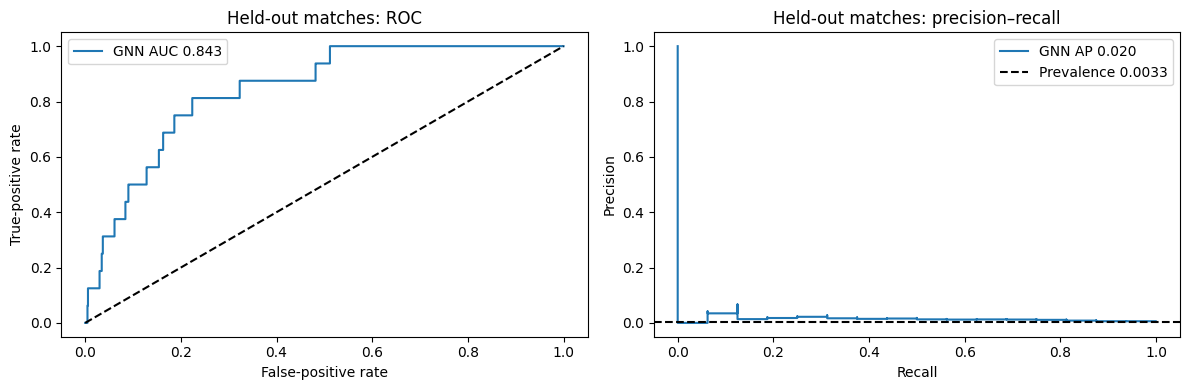

1780

In [30]:
val_logits = predict_graph_model(real_model, graph_data, val_idx)
calibration = fit_calibrator(val_logits, graph_data["y"][val_idx])
test_logits = predict_graph_model(real_model, graph_data, test_idx)
test_probability = logistic(calibration[0] * test_logits + calibration[1])
test_y = graph_data["y"][test_idx]
rank = ranking_metrics(test_y, test_probability)
baseline_probability = np.full(len(test_y), graph_data["y"][train_idx].mean())


def probability_scores(y, p):
    p = np.clip(p, 1e-8, 1 - 1e-8)
    return {
        "log_loss": float(np.mean(-y * np.log(p) - (1 - y) * np.log(1 - p))),
        "Brier_score": float(np.mean((p - y) ** 2)),
        "mean_prediction": float(p.mean()),
    }


metrics_table = pd.DataFrame(
    [
        {
            "model": "Real trained frame GNN",
            "ROC_AUC": rank["roc_auc"],
            "average_precision": rank["average_precision"],
            **probability_scores(test_y, test_probability),
        },
        {
            "model": "Training-prevalence baseline",
            "ROC_AUC": 0.5,
            "average_precision": float(test_y.mean()),
            **probability_scores(test_y, baseline_probability),
        },
    ]
)
display(metrics_table)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(rank["fpr"], rank["tpr"], label=f"GNN AUC {rank['roc_auc']:.3f}")
axs[0].plot([0, 1], [0, 1], "k--")
axs[0].set(
    xlabel="False-positive rate",
    ylabel="True-positive rate",
    title="Held-out matches: ROC",
)
axs[0].legend()
axs[1].step(
    rank["recall"],
    rank["precision"],
    where="post",
    label=f"GNN AP {rank['average_precision']:.3f}",
)
axs[1].axhline(
    test_y.mean(), ls="--", c="black", label=f"Prevalence {test_y.mean():.4f}"
)
axs[1].set(
    xlabel="Recall", ylabel="Precision", title="Held-out matches: precision–recall"
)
axs[1].legend()
plt.tight_layout()
plt.show()
result_report = {
    "source": "SkillCorner open tracking",
    "revision": REVISION,
    "target": "Goal-shot event by current possession team within next 100 frames (10 seconds), same period",
    "label_caveat": "Goal-marker/shot alignment reconciles final scores but is not video-verified timing",
    "samples": len(graph_data["y"]),
    "positive_states": int(graph_data["y"].sum()),
    "split": split_table.to_dict(orient="records"),
    "train_matches": train_matches.tolist(),
    "validation_matches": val_matches.tolist(),
    "test_matches": test_matches.tolist(),
    "calibration": calibration.tolist(),
    "test_metrics": metrics_table.to_dict(orient="records"),
    "own_real_gnn_inference": True,
}
result_folder = ROOT / "outputs/methods"
result_folder.mkdir(parents=True, exist_ok=True)
(result_folder / "graph_epv_real_results.json").write_text(
    json.dumps(result_report, indent=2) + "\n", encoding="utf-8"
)


## 16. Predict an unseen goal build-up and a non-goal possession
Match 1925299 is entirely held out from training and calibration. Select its goal build-up by observed event context, not by a high model prediction. Also show a preselected non-goal spell near the beginning of the same match. This is an explanatory case pair, not an unbiased performance sample.

Run the frozen model separately on each eligible native-rate frame. Unknown possession or invalid coverage produces a **gap**, not an interpolated probability. The chart shows actual predictions of **our trained model**, not supplied SkillCorner EPV. For display, keep the same attacking team's perspective throughout the selected sequence.

In [31]:
example_match = 1925299
assert (
    example_match in test_matches
    and example_match not in train_matches
    and example_match not in val_matches
)
example_metadata, example_events, _, example_folder = cached_match_inputs(
    example_match, GRAPH_CACHE
)
example_goals, example_audit = audited_goal_events(example_events, example_metadata)
goal = example_goals[0]
possessions = example_events[
    (example_events.event_type == "player_possession")
    & (example_events.period == goal["period"])
].sort_values("frame_start")
previous_opponents = possessions[
    (possessions.team_id != goal["team_id"])
    & (possessions.frame_end < goal["frame"])
    & (possessions.frame_end >= goal["frame"] - 300)
]
if len(previous_opponents):
    start_after = int(previous_opponents.frame_end.max())
else:
    start_after = goal["frame"] - 300
build_up = possessions[
    (possessions.team_id == goal["team_id"])
    & (possessions.frame_start > start_after)
    & (possessions.frame_start <= goal["frame"])
]
start = max(goal["frame"] - 300, int(build_up.frame_start.min()))
end = goal["frame"]
goal_frames = json.loads(
    (example_folder / "goal_window_frames_v1.json").read_text(encoding="utf-8")
)
goal_sequence = []
for r in goal_frames.values():
    if int(r["period"]) == goal["period"] and start <= int(r["frame"]) <= end:
        goal_sequence.append(r)


def frame_number(record):
    return record["frame"]


goal_sequence.sort(key=frame_number)
non_goal_sequence = []
for r in raw:
    if r.get("period") == 1 and 281 <= int(r["frame"]) <= 567:
        non_goal_sequence.append(r)
non_goal_team = int(example_metadata["away_team"]["id"])


def predict_tracking_sequence(frames, metadata, team):
    valid_graphs = []
    indices = []
    probability = np.full(len(frames), np.nan)
    for i, frame in enumerate(frames):
        graph = frame_to_graph(frame, metadata)
        if graph is not None and graph[3] == team:
            valid_graphs.append(graph)
            indices.append(i)
    if valid_graphs:
        X_items_1 = []
        for g in valid_graphs:
            X_items_1.append(g[0])
        X = np.array(X_items_1)
        A_items_1 = []
        for g in valid_graphs:
            A_items_1.append(g[1])
        A = np.array(A_items_1)
        P_items_1 = []
        for g in valid_graphs:
            P_items_1.append(g[2])
        P = np.array(P_items_1)
        logits = graph_model_forward(real_model, X, A @ X, P)[0]
        (probability[indices]) = logistic(calibration[0] * logits + calibration[1])
    result_items_1 = []
    for f in frames:
        result_items_1.append(int(f["frame"]))
    return pd.DataFrame({"frame": result_items_1, "probability": probability})


goal_predictions = predict_tracking_sequence(
    goal_sequence, example_metadata, goal["team_id"]
)
non_goal_predictions = predict_tracking_sequence(
    non_goal_sequence, example_metadata, non_goal_team
)
print(
    "Goal sequence:",
    start,
    "to",
    end,
    "| scored frames:",
    int(goal_predictions.probability.notna().sum()),
    "/",
    len(goal_predictions),
)
print(
    "Non-goal sequence scored frames:",
    int(non_goal_predictions.probability.notna().sum()),
    "/",
    len(non_goal_predictions),
)
display(goal_predictions.dropna().head(10))


Goal sequence: 44073 to 44303 | scored frames: 207 / 231
Non-goal sequence scored frames: 237 / 287


,frame,probability
0,44073,0.000379
1,44074,0.000361
2,44075,0.000365
3,44076,0.000352
4,44077,0.000353
5,44078,0.000336
6,44079,0.000330
7,44080,0.000350
8,44081,0.000338
9,44082,0.000314


## 17. Actual results: EPV over time with pitch snapshots
EPV here means the trained model's estimated ten-second scoring probability. Read the prediction curve together with player/ball positions. The shaded goal window marks the reconstructed target interval for interpretation; it was never a model input. If the model misses a buildup or spikes on a non-goal sequence, that is part of its observed limitation.

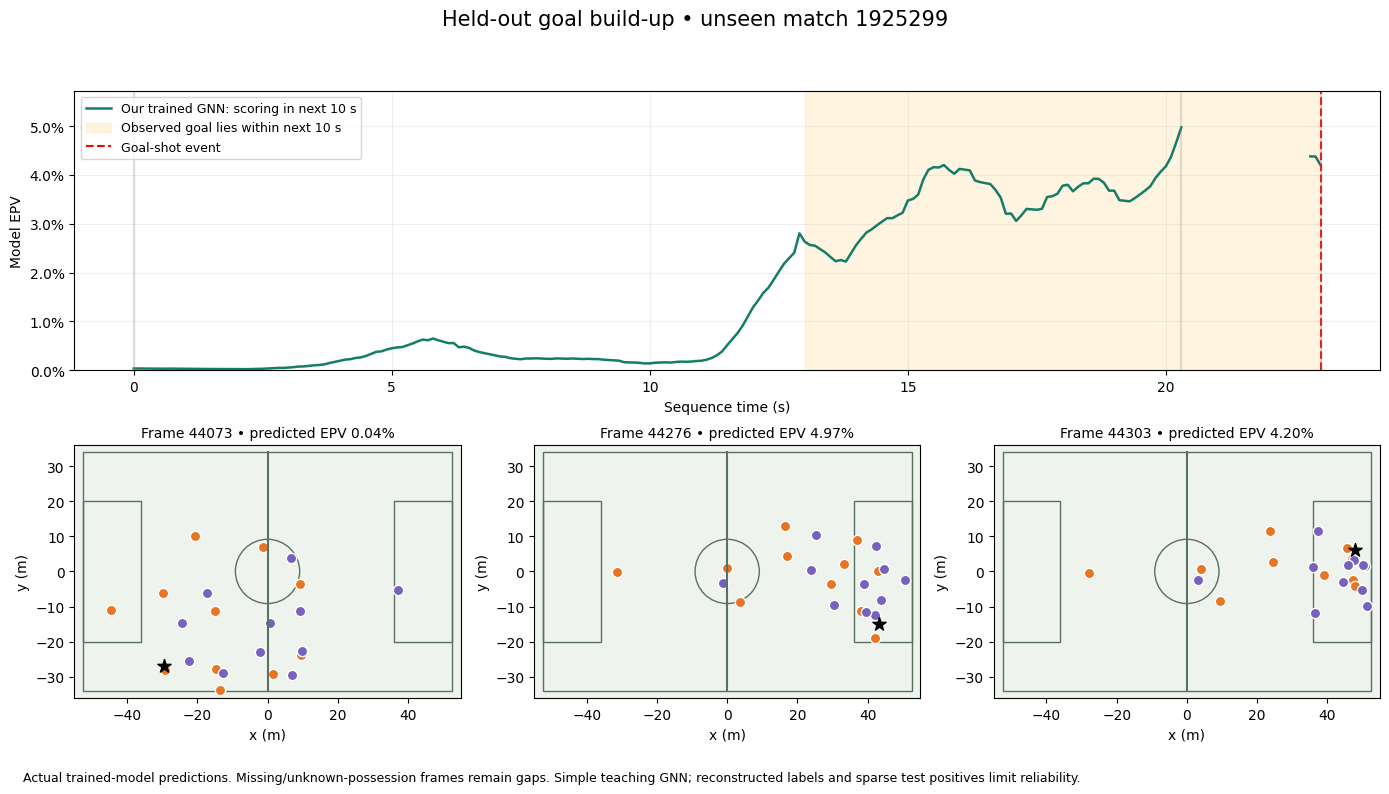

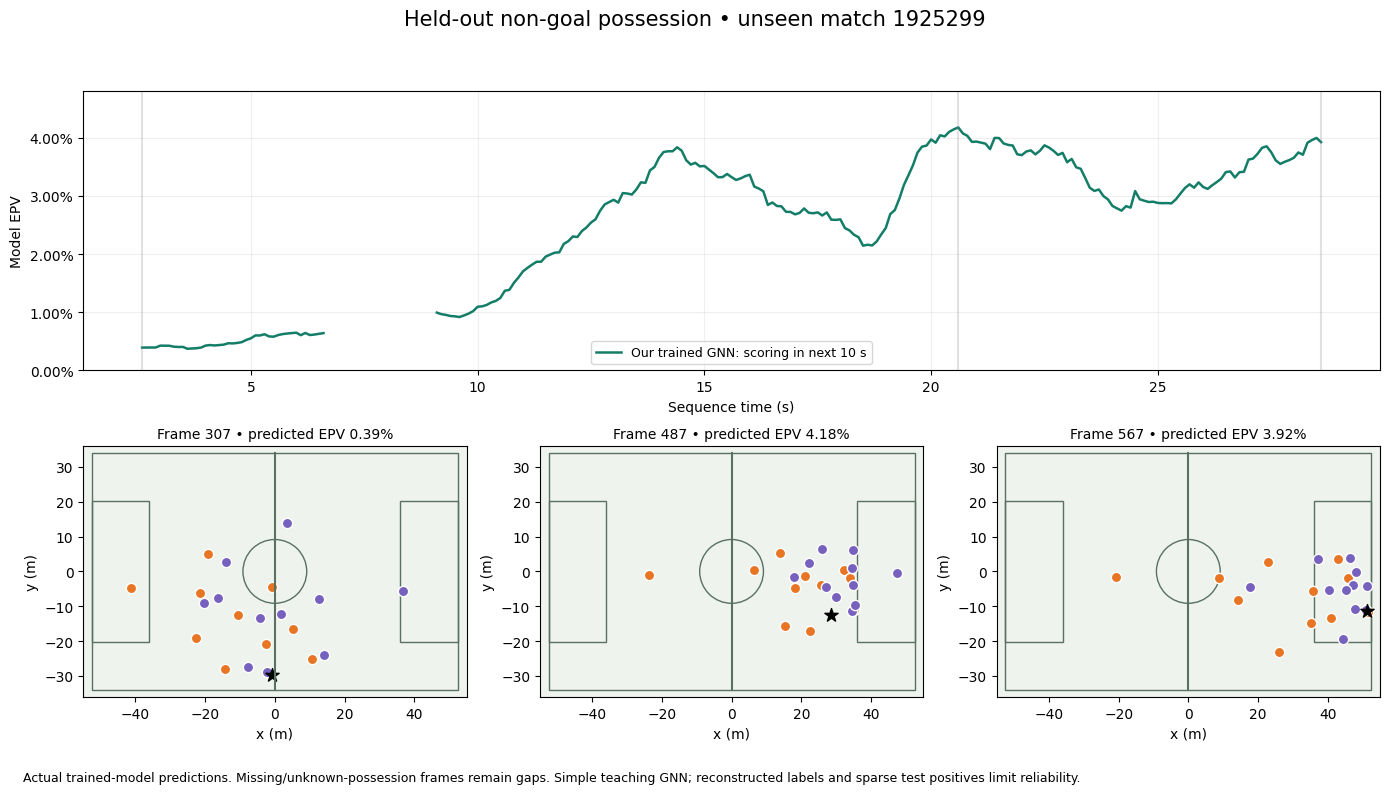

,case,frames,scored_frames,peak_prediction
0,goal build-up,231,207,0.049707
1,non-goal possession,287,237,0.041768


2083

In [32]:
def draw_real_frame(ax, frame, team, metadata):
    period = int(frame["period"])
    home_left = metadata["home_team_side"][period - 1] == "right_to_left"
    home = int(metadata["home_team"]["id"])
    if team == home:
        left = home_left
    else:
        left = not home_left
    if left:
        sign = -1
    else:
        sign = 1
    player_meta = {}
    for p in metadata["players"]:
        (player_meta[str(p["id"])]) = p
    pitch(ax)
    if team == home:
        loop_value_1 = int(metadata["away_team"]["id"])
    else:
        loop_value_1 = home
    for tid, color in [(team, "#e87524"), (loop_value_1, "#7761be")]:
        xy_items_1 = []
        for p in frame["player_data"]:
            if (
                p.get("x") is not None
                and p.get("y") is not None
                and (str(p["player_id"]) in player_meta)
                and (int(player_meta[str(p["player_id"])]["team_id"]) == tid)
            ):
                xy_items_1.append([p["x"], p["y"]])
        xy = np.array(xy_items_1) * sign
        if len(xy):
            ax.scatter(xy[:, 0], xy[:, 1], c=color, s=55, edgecolors="white")
    ball = frame.get("ball_data", {})
    if ball.get("x") is not None and ball.get("y") is not None:
        ax.scatter(sign * ball["x"], sign * ball["y"], c="black", marker="*", s=100)


def plot_real_sequence(
    frames, prediction, team, title, goal_frame=None, save_name=None
):
    origin = int(prediction.frame.iloc[0])
    times = (prediction.frame - origin) / 10
    fig = plt.figure(figsize=(14, 8))
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.25])
    ax = fig.add_subplot(grid[0, :])
    ax.plot(
        times,
        prediction.probability,
        c="#147d68",
        lw=1.8,
        label="Our trained GNN: scoring in next 10 s",
    )
    if goal_frame is not None:
        ax.axvspan(
            (goal_frame - 100 - origin) / 10,
            (goal_frame - origin) / 10,
            alpha=0.12,
            color="orange",
            label="Observed goal lies within next 10 s",
        )
        ax.axvline(
            (goal_frame - origin) / 10, c="red", ls="--", label="Goal-shot event"
        )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(
        xlabel="Sequence time (s)",
        ylabel="Model EPV",
        ylim=(0, max(0.01, float(prediction.probability.max()) * 1.15)),
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
    valid_rows = prediction.dropna()
    choices = [
        int(valid_rows.index[0]),
        int(valid_rows.probability.idxmax()),
        int(valid_rows.index[-1]),
    ]
    for j, i in enumerate(choices):
        bx = fig.add_subplot(grid[1, j])
        draw_real_frame(bx, frames[i], team, example_metadata)
        bx.set_title(
            f"Frame {frames[i]['frame']} • predicted EPV {prediction.loc[i,'probability']:.2%}",
            fontsize=10,
        )
        ax.axvline(times.loc[i], c="#888", alpha=0.25)
    fig.suptitle(title + " • unseen match 1925299", fontsize=15)
    fig.text(
        0.02,
        0.015,
        "Actual trained-model predictions. Missing/unknown-possession frames remain gaps. Simple teaching GNN; reconstructed labels and sparse test positives limit reliability.",
        fontsize=9,
    )
    fig.tight_layout(rect=(0, 0.04, 1, 0.94))
    if save_name:
        folder = ROOT / "assets/methods"
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / (save_name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


plot_real_sequence(
    goal_sequence,
    goal_predictions,
    goal["team_id"],
    "Held-out goal build-up",
    goal["frame"],
    "graph_epv_real_goal",
)
plot_real_sequence(
    non_goal_sequence,
    non_goal_predictions,
    non_goal_team,
    "Held-out non-goal possession",
    None,
    "graph_epv_real_non_goal",
)
case_results = [
    {
        "case": "goal build-up",
        "frames": len(goal_predictions),
        "scored_frames": int(goal_predictions.probability.notna().sum()),
        "peak_prediction": float(goal_predictions.probability.max()),
    },
    {
        "case": "non-goal possession",
        "frames": len(non_goal_predictions),
        "scored_frames": int(non_goal_predictions.probability.notna().sum()),
        "peak_prediction": float(non_goal_predictions.probability.max()),
    },
]
display(pd.DataFrame(case_results))
(result_report["examples"]) = case_results
(result_folder / "graph_epv_real_results.json").write_text(
    json.dumps(result_report, indent=2) + "\n", encoding="utf-8"
)


## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,2,44073,44276,871,20.4
1,1,2,44277,44300,1802,2.4
2,2,2,44301,44303,871,0.3


,event_id,event_type,frame_start,frame_end
3880,8_783,player_possession,44073,44073
3881,7_2046,passing_option,44073,44073
3882,9_679,on_ball_engagement,44092,44095
3883,8_784,player_possession,44095,44095
3884,7_2047,passing_option,44095,44095
3885,7_2048,passing_option,44095,44095
3886,8_785,player_possession,44150,44150
3887,7_2049,passing_option,44150,44150
3888,7_2050,passing_option,44150,44150
3889,7_2051,passing_option,44150,44150


Recomputed overlays on 77 real frames; first/last: (2, 44073) (2, 44301)


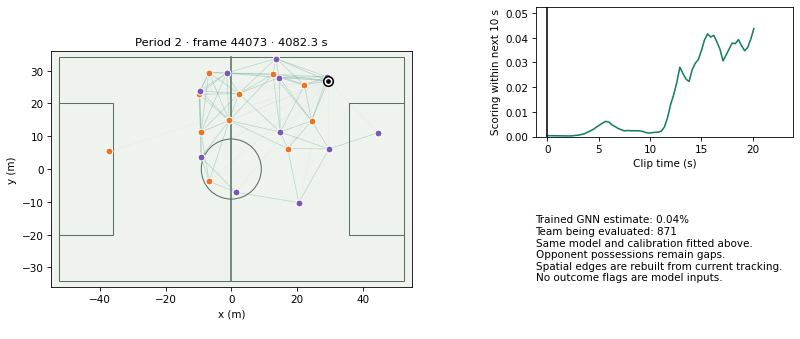

In [33]:
method_name = "graph_epv"
if PERIOD is None:
    if SEQUENCE == "goal":
        PERIOD = int(goal_sequence[0]["period"])
    else:
        PERIOD = 1
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

players_by_id = {}
for player in metadata["players"]:
    (players_by_id[str(player["id"])]) = player
home_team_id = int(metadata["home_team"]["id"])
away_team_id = int(metadata["away_team"]["id"])
tracking_records = list(raw)
if method_name == "graph_epv":
    unique_records_by_key = {}
    for record in raw + goal_sequence:
        if record.get("period") is not None:
            (unique_records_by_key[int(record["period"]), int(record["frame"])]) = (
                record
            )
    tracking_records = list(unique_records_by_key.values())
source_frames = {}
for record in tracking_records:
    if record.get("period") is not None:
        (source_frames[int(record["period"]), int(record["frame"])]) = record
frames_by_key = {}
for frame_key, record in source_frames.items():
    position_flags = []
    for player in record["player_data"]:
        position_flags.append(
            player.get("x") is not None and player.get("y") is not None
        )
    if (
        frame_key[0] == PERIOD
        and len(record.get("player_data", [])) == 22
        and all(position_flags)
        and (record.get("ball_data", {}).get("x") is not None)
        and (record["ball_data"].get("y") is not None)
        and (record.get("timestamp") is not None)
    ):
        (frames_by_key[frame_key]) = record
assert frames_by_key, "No complete frames for PERIOD in the cached source."


def tracking_time(record):
    return pd.to_timedelta(record["timestamp"]).total_seconds()


def possession_team(record):
    """Translate the source's team label into the corresponding team identifier."""
    group = record.get("possession", {}).get("group")
    if group == "home team":
        return home_team_id
    if group == "away team":
        return away_team_id
    return None


def attack_direction(team, period):
    """Return -1 for attacks to the left and +1 for attacks to the right."""
    home_attacks_left = metadata["home_team_side"][period - 1] == "right_to_left"
    if team == home_team_id:
        attacks_left = home_attacks_left
    else:
        attacks_left = not home_attacks_left
    if attacks_left:
        return -1
    return 1


def players_at_frame(frame_key):
    """Make a player table and estimate velocity using the immediately previous frame."""
    record = frames_by_key[frame_key]
    period, frame_number = frame_key
    previous_record = source_frames.get((period, frame_number - 1))
    previous_players = {}
    elapsed_seconds = np.nan
    if previous_record is not None:
        for player in previous_record.get("player_data", []):
            (previous_players[str(player["player_id"])]) = player
        if previous_record.get("timestamp"):
            elapsed_seconds = tracking_time(record) - tracking_time(previous_record)

    player_rows = []
    for player in record["player_data"]:
        player_id = str(player["player_id"])
        previous_player = previous_players.get(player_id, {})
        velocity = np.array([np.nan, np.nan])
        valid_time = 0.05 <= elapsed_seconds <= 0.15
        has_previous_x = previous_player.get("x") is not None
        has_previous_y = previous_player.get("y") is not None
        if valid_time and has_previous_x and has_previous_y:
            current_position = np.array([player["x"], player["y"]])
            previous_position = np.array([previous_player["x"], previous_player["y"]])
            velocity = (current_position - previous_position) / elapsed_seconds
        player_rows.append(
            {
                "player_id": player_id,
                "team_id": int(players_by_id[player_id]["team_id"]),
                "x": player["x"],
                "y": player["y"],
                "vx": velocity[0],
                "vy": velocity[1],
                "is_detected": player.get("is_detected"),
            }
        )
    return pd.DataFrame(player_rows)


def draw_tracking_frame(axis, frame_key):
    tracking_record = frames_by_key[frame_key]
    player_table = players_at_frame(frame_key)
    pitch(axis)
    for team_id, color in [(home_team_id, "#e87524"), (away_team_id, "#7959b5")]:
        team_players = player_table[player_table.team_id == team_id]
        axis.scatter(
            team_players.x, team_players.y, c=color, edgecolors="white", s=44, zorder=5
        )
    ball_position = np.array(
        [tracking_record["ball_data"]["x"], tracking_record["ball_data"]["y"]]
    )
    axis.scatter(*ball_position, s=85, c="white", edgecolors="black", lw=1.5, zorder=10)
    axis.scatter(*ball_position, s=12, c="black", zorder=11)
    axis.set_title(
        f"Period {frame_key[0]} · frame {frame_key[1]} · {tracking_time(tracking_record):.1f} s",
        fontsize=11,
    )
    return player_table, ball_position, tracking_record


# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog = []
previous = None
group = None
for frame_key in sorted(frames_by_key):
    record = frames_by_key[frame_key]
    current_possession_team = possession_team(record)
    continuous = (
        previous is not None
        and frame_key[1] == previous[1] + 1
        and 0 < tracking_time(record) - tracking_time(frames_by_key[previous]) <= 0.15
    )
    if not continuous or current_possession_team != group:
        example_catalog.append(
            dict(
                possession_index=len(example_catalog),
                period=frame_key[0],
                start_frame=frame_key[1],
                end_frame=frame_key[1],
                team_id=current_possession_team,
            )
        )
    else:
        (example_catalog[-1]["end_frame"]) = frame_key[1]
    previous = frame_key
    group = current_possession_team
available_possessions = pd.DataFrame(example_catalog)
(available_possessions["duration_s"]) = (
    available_possessions.end_frame - available_possessions.start_frame + 1
) / 10
if "events" in globals():
    available_events_items_1 = []
    for k in frames_by_key:
        available_events_items_1.append(k[1])
    available_events = events[
        (events.period == PERIOD) & events.frame_start.isin(available_events_items_1)
    ].copy()
else:
    available_events = pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):
    display(
        available_events[["event_id", "event_type", "frame_start", "frame_end"]].head(
            10
        )
    )

clip_start_frame = None
clip_stop_frame = None
example_action = None
if method_name == "formation":
    available_windows = timeline[timeline.period == PERIOD].copy()
    display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):
        raise ValueError(
            "FORMATION_WINDOW must be a qualifying window in available_windows."
        )
    example_window_data = team_data[
        (team_data.period_id == PERIOD)
        & (team_data.window == FORMATION_WINDOW)
        & (team_data.team_in_possession == 871)
    ]
    example_med = example_window_data.groupby("player_id")[["cx", "cy"]].median()
    example_points = -example_med.to_numpy()
    example_fits = []
    for name, t in templates.items():
        cost = ((example_points[:, None] - t[None]) ** 2).sum(2)
        rr, cc = linear_sum_assignment(cost)
        example_fits.append((name, float(np.sqrt(cost[rr, cc].mean())), cc))

    def assignment_error(fit):
        return fit[1]

    example_fits.sort(key=assignment_error)
    example_best = example_fits[0]
    candidates = []
    for k in frames_by_key:
        if (
            FORMATION_WINDOW * 30
            <= tracking_time(frames_by_key[k])
            < (FORMATION_WINDOW + 1) * 30
        ):
            candidates.append(k[1])
    assert candidates, "Selected formation window has no complete animation frames."
    clip_start_frame = min(candidates)
    clip_stop_frame = max(candidates)
elif method_name == "events":
    display(passes.reset_index(names="pass_index").head(12))
    if len(passes):
        assert 0 <= PASS_INDEX < len(passes), "PASS_INDEX is a row number in passes."
        example_action = passes.iloc[PASS_INDEX]
        clip_start_frame = max(int(example_action.release) - 8, 0)
        clip_stop_frame = int(example_action.reception) + 12
elif method_name == "xt":
    example_actions_items_1 = []
    for k in frames_by_key:
        example_actions_items_1.append(k[1])
    example_actions = (
        events[
            (events.event_type == "player_possession")
            & (events.end_type == "pass")
            & (events.pass_outcome == "successful")
            & (events.period == PERIOD)
            & events.frame_end.isin(example_actions_items_1)
        ]
        .dropna(
            subset=[
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        )
        .copy()
    )
    display(
        example_actions[
            [
                "event_id",
                "frame_end",
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        ].head(12)
    )
    assert len(example_actions), "No completed actions with endpoint coverage."
    if EVENT_ID is None:
        example_action = example_actions.iloc[0]
    else:
        example_action = example_actions[example_actions.event_id == EVENT_ID].iloc[0]
    clip_start_frame = int(example_action.frame_end) - 5
elif method_name == "graph_epv" and SEQUENCE == "goal":
    clip_start_frame = int(goal_sequence[0]["frame"])
    clip_stop_frame = int(goal_sequence[-1]["frame"])
elif method_name == "graph_epv" and SEQUENCE == "non_goal":
    clip_start_frame = int(non_goal_sequence[0]["frame"])
    clip_stop_frame = int(non_goal_sequence[-1]["frame"])

if EVENT_ID is not None and method_name != "xt":
    chosen = available_events[available_events.event_id == EVENT_ID]
    assert (
        len(chosen) == 1
    ), "Choose EVENT_ID from available_events.event_id, not a row number."
    clip_start_frame = int(chosen.frame_start.iloc[0])
    clip_stop_frame = int(chosen.frame_end.iloc[0]) + 10
if POSSESSION_INDEX is not None:
    chosen = available_possessions[
        available_possessions.possession_index == POSSESSION_INDEX
    ]
    assert len(chosen) == 1, "Choose POSSESSION_INDEX from available_possessions."
    clip_start_frame = int(chosen.start_frame.iloc[0])
    clip_stop_frame = int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame = int(FRAME_ID)
    clip_stop_frame = None
if clip_start_frame is None:
    clip_start_frame = int(frame_id)
if (PERIOD, clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible = []
    for k in sorted(frames_by_key):
        if k[1] >= clip_start_frame and (
            clip_stop_frame is None or k[1] <= clip_stop_frame
        ):
            possible.append(k[1])
    assert possible, "No covered frame for this selection."
    clip_start_frame = possible[0]
clip_keys = []
for f in range(clip_start_frame, clip_start_frame + max(2, int(DURATION_S * 10))):
    frame_key = (PERIOD, f)
    if frame_key not in frames_by_key or (
        clip_stop_frame is not None and f > clip_stop_frame
    ):
        break
    if (
        clip_keys
        and not 0
        < tracking_time(frames_by_key[frame_key])
        - tracking_time(frames_by_key[clip_keys[-1]])
        <= 0.15
    ):
        break
    clip_keys.append(frame_key)
assert (
    len(clip_keys) >= 2
), "Selection ends at a coverage boundary; choose another covered start."
assert FRAME_STRIDE >= 1
clip_keys = clip_keys[::FRAME_STRIDE]
assert len(clip_keys) >= 2, "Reduce FRAME_STRIDE or increase clip duration."
if TEAM_ID is not None:
    selected_team = TEAM_ID
else:
    selected_team = possession_team(frames_by_key[clip_keys[0]]) or home_team_id
if PLAYER_ID is not None:
    focus_player_id = str(PLAYER_ID)
else:
    focus_player_id_items_1 = []
    for player in metadata["players"]:
        if int(player["team_id"]) == selected_team:
            focus_player_id_items_1.append(player["id"])
    if len(focus_player_id_items_1) > 0:
        focus_player_id_first_match_2 = focus_player_id_items_1[0]
    else:
        raise ValueError(
            "No matching item was found. Check the available data or your selection."
        )
    focus_player_id = str(focus_player_id_first_match_2)
if method_name == "physical" and PLAYER_ID is None:
    focus_player_id = str(
        summary.sort_values("sprint_m", ascending=False).player_id.iloc[0]
    )
example_origin = tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys = clip_keys

if (
    TEAM_ID is None
    and SEQUENCE == "goal"
    and FRAME_ID is None
    and POSSESSION_INDEX is None
    and EVENT_ID is None
):
    selected_team = int(goal["team_id"])
example_fixed_team = selected_team
example_sequence_frames = []
for k in clip_keys:
    example_sequence_frames.append(frames_by_key[k])
example_sequence_prediction = predict_tracking_sequence(
    example_sequence_frames, metadata, example_fixed_team
)
example_probability_by_key = dict(
    zip(clip_keys, example_sequence_prediction.probability)
)


def draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis):
    for plot_axis in [pitch_axis, detail_axis, summary_axis]:
        plot_axis.clear()
    player_table, ball_position, tracking_record = draw_tracking_frame(
        pitch_axis, frame_key
    )
    clip_seconds = tracking_time(tracking_record) - example_origin
    summary_axis.axis("off")
    graph = frame_to_graph(tracking_record, metadata)
    if graph is not None:
        node_positions = np.vstack(
            [
                player_table.sort_values("player_id")[["x", "y"]].to_numpy(),
                ball_position,
            ]
        )
        pairwise_distance = np.linalg.norm(
            node_positions[:, None] - node_positions[None], axis=-1
        )
        for source_node, target_node in zip(
            *np.where(np.triu(pairwise_distance <= 20, 1))
        ):
            pitch_axis.plot(
                node_positions[[source_node, target_node], 0],
                node_positions[[source_node, target_node], 1],
                c="#147d68",
                alpha=0.25,
                lw=0.7,
                zorder=1,
            )
        for point in node_positions[:-1]:
            pitch_axis.plot(
                [point[0], ball_position[0]],
                [point[1], ball_position[1]],
                c="#888",
                alpha=0.08,
                lw=0.5,
                zorder=1,
            )
    clip_times = []
    for sample_key in clip_keys:
        clip_times.append(tracking_time(frames_by_key[sample_key]) - example_origin)
    probabilities = []
    for sample_key in clip_keys:
        probabilities.append(example_probability_by_key[sample_key])
    detail_axis.plot(clip_times, probabilities, c="#147d68")
    detail_axis.axvline(clip_seconds, c="black")
    if np.isfinite(probabilities).any():
        display_value_1 = max(0.01, float(np.nanmax(probabilities)) * 1.2)
    else:
        display_value_1 = 0.01
    detail_axis.set(
        xlabel="Clip time (s)",
        ylabel="Scoring within next 10 s",
        ylim=(0, display_value_1),
    )
    current_probability = example_probability_by_key[frame_key]
    if np.isfinite(current_probability):
        display_value_1 = f"Trained GNN estimate: {current_probability:.2%}"
    else:
        display_value_1 = "Prediction unavailable at this frame."
    summary_axis.text(
        0,
        0.9,
        display_value_1
        + f"\nTeam being evaluated: {example_fixed_team}\nSame model and calibration fitted above.\nOpponent possessions remain gaps.\nSpatial edges are rebuilt from current tracking.\nNo outcome flags are model inputs.",
        va="top",
        fontsize=10,
    )


def make_example_figure(frame_key):
    figure = plt.figure(figsize=(11, 5.7), dpi=75)
    layout = figure.add_gridspec(2, 2, width_ratios=[1.4, 1], hspace=0.5)
    pitch_axis = figure.add_subplot(layout[:, 0])
    detail_axis = figure.add_subplot(layout[0, 1])
    summary_axis = figure.add_subplot(layout[1, 1])
    draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis)
    figure.subplots_adjust(
        left=0.07, right=0.97, bottom=0.14, top=0.9, wspace=0.4, hspace=0.65
    )
    return figure, (pitch_axis, detail_axis, summary_axis)


# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0], clip_keys[-1]]:
    example_check_figure, _ = make_example_figure(example_check_key)
    plt.close(example_check_figure)
print(
    "Recomputed overlays on",
    len(clip_keys),
    "real frames; first/last:",
    clip_keys[0],
    clip_keys[-1],
)
example_static, _ = make_example_figure(clip_keys[0])
plt.show()
example_fig, example_axes = make_example_figure(clip_keys[0])


def update_animation(i):
    draw_method_overlay(clip_keys[i], *example_axes)


animation = FuncAnimation(
    example_fig,
    update_animation,
    frames=len(clip_keys),
    interval=100 * FRAME_STRIDE,
    repeat=False,
    blit=False,
)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10 / FRAME_STRIDE, default_mode="once")))


## Interpretation and limitations
- This notebook now includes **real trained GNN predictions** for previously unseen SkillCorner matches. The earlier synthetic section only explains derivatives; it is not the source of the final curves.
- It is a small independent architecture, not Bekkers' CrystalGraph weights or the provider's model. Its target is scoring within ten seconds, not the supplied SkillCorner thirty-second / next-interruption EPV.
- Goal timing is reconstructed from markers and nearby shot events, with final-score reconciliation. Four matches fail that audit and are excluded. Scores matching does not certify exact event timing or every shot identity.
- There are only sixteen included matches and few independent goals; positive frames are strongly correlated. ROC/AUC can look encouraging while precision is low. Test prevalence, average precision, log loss and Brier score are shown to make that limitation visible. No claim of production quality or GNN superiority over a strong ball-location baseline is supported here.
- Current-frame geometry uses both observed and extrapolated tracks. Unknown possession, incomplete players and period endings are masked. Training is sampled every two seconds; the animation applies the frozen model to denser eligible frames from the held-out sequence, which are not extra independent test observations.
- Validation selects the checkpoint and calibrates scores; test matches are used only for evaluation and the requested retrospective examples. Cases are selected for explanation, not unbiased proof of performance. The goal-time shading is a label overlay, never an input.

Sources: [SkillCorner open data](https://github.com/SkillCorner/opendata), [Joris Bekkers' GraphEPV talk](https://rawcdn.githack.com/UnravelSports/keynotes/main/html/20250607-PyData-London.html). Raw data remain excluded from the published repository.

On these held-out matches, the model improves ranking and log loss over a constant prevalence baseline, but **Brier score does not improve**. Treat the animation as a transparent result of this limited model, not evidence of dependable probabilities.